**Ousmane COUNDOUL**

***Parcours Data Scientist***

***OpenClassrooms***

***Soutenance 2026 - 11 - 15***

<div class="alert alert-block alert-info"> 
        <center><h2><font color="red"> Projet 8 : Confirmation de compétences en MLOps (Partie 2/2)</font></h2></center>
</div>

**Dépôt GitHub du projet :** [github.com/ouse4444/OC_DS_P8](https://github.com/ouse4444/OC_DS_P8)

# Analyse de la dérive des données de production
*Ce notebook présente l'analyse de la dérive des données de production.*

**Objectif.** Vérifier si les données reçues par l'API en production ressemblent aux données sur lesquelles le modèle a été entraîné, et mesurer l'effet d'un éventuel changement sur les prédictions.

**Données comparées.**
- **Référence** : un échantillon de 20 000 clients du jeu d'entraînement du Projet 6 (même découpage 80/20, même graine aléatoire).
- **Production** : les requêtes reçues par l'API déployée sur Azure, enregistrées dans la base PostgreSQL. Elles proviennent d'une simulation de trafic en deux lots : un lot **normal** (clients du jeu de test, tels quels) et un lot **drift** (clients modifiés selon un scénario de changement de population).

**Méthode.** La bibliothèque Evidently compare la distribution de chaque variable entre la référence et la production, avec un test adapté à son type. Les résultats sont croisés avec l'importance des variables dans le modèle, puis avec la performance réelle mesurée sur les données de production.

## 1. Environnement et connexion à la base de production

L'adresse de la base de données contient un mot de passe : elle est lue dans le fichier `.env`, exclu du dépôt Git, et n'apparaît jamais dans le notebook.

In [1]:
# Bibliothèques
import json
import os
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import mlflow.sklearn
import numpy as np
import pandas as pd
from dotenv import load_dotenv
from evidently import DataDefinition, Dataset, Report
from evidently.presets import DataDriftPreset
from sklearn.metrics import recall_score, roc_auc_score
from sklearn.model_selection import train_test_split
from sqlalchemy import create_engine, text

# Avertissements connus et sans effet (mêmes filtres que l'API)
warnings.filterwarnings("ignore", message="X does not have valid feature names")
warnings.filterwarnings("ignore", message="Downcasting behavior", category=FutureWarning)

# Chemins : le notebook est dans notebooks/, la racine du projet est le dossier parent
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT / "src"))
from credit_scoring.config import RANDOM_STATE, TARGET  # noqa: E402

MODEL_DIR = PROJECT_ROOT / "model"
REFERENCE_DATA = PROJECT_ROOT / "data" / "processed" / "application_train_enriched.parquet"
SIMULATION_RESULTS = PROJECT_ROOT / "data" / "simulation" / "simulation_results.csv"
REPORTS_DIR = PROJECT_ROOT / "monitoring" / "reports"
REPORTS_DIR.mkdir(parents=True, exist_ok=True)

# Seuil de décision du modèle (Projet 6)
THRESHOLD = 0.36

# Connexion à la base de production : l'adresse, qui contient le mot de passe, est lue
# dans le fichier .env (non versionné), jamais écrite dans le notebook
load_dotenv(PROJECT_ROOT / ".env")
engine = create_engine(os.environ["DATABASE_URL"])

print(f"Racine du projet : {PROJECT_ROOT}")
print(f"Dossier des rapports Evidently : {REPORTS_DIR.relative_to(PROJECT_ROOT)}")

Racine du projet : /Users/ousmane/Desktop/OPENCLASSROOMS/Data Scientist Machine learning/OC_DS_P8
Dossier des rapports Evidently : monitoring/reports


## 2. Le modèle de production et ses variables

Le modèle est chargé depuis le même dossier que l'API. Il attend **199 variables** en entrée, puis en construit **7 autres** lui-même (ratios financiers, âge et ancienneté en années). Ces 7 variables construites sont aussi analysées : un ratio comme crédit sur revenu peut dériver fortement même si chacune de ses composantes ne dérive que modérément.

In [2]:
# Chargement du modèle de production (même dossier que celui de l'API)
model = mlflow.sklearn.load_model(str(MODEL_DIR))
feature_builder = model.named_steps["preparation"].named_steps["features"]
column_transformer = model.named_steps["preparation"].named_steps["preparation"]

# Variables envoyées à l'API : celles attendues par le préprocesseur, sauf les 7 variables
# construites par le modèle lui-même (ratios, âge en années, ancienneté en années)
ENGINEERED = ["RATIO_CREDIT_REVENU", "RATIO_ANNUITE_REVENU", "RATIO_ANNUITE_CREDIT",
              "REVENU_PAR_PERSONNE", "RATIO_EMPLOI_AGE", "AGE_ANNEES", "ANCIENNETE_EMPLOI_ANNEES"]
CATEGORICAL = list(next(cols for name, _, cols in column_transformer.transformers_ if name == "cat"))
INPUT_FEATURES = [c for c in column_transformer.feature_names_in_ if c not in ENGINEERED]
NUMERIC = [c for c in INPUT_FEATURES if c not in CATEGORICAL] + ENGINEERED

print(f"Variables envoyées à l'API : {len(INPUT_FEATURES)} "
      f"({len(CATEGORICAL)} catégorielles, {len(INPUT_FEATURES) - len(CATEGORICAL)} numériques)")
print(f"Variables construites par le modèle : {len(ENGINEERED)}")

Variables envoyées à l'API : 199 (11 catégorielles, 188 numériques)
Variables construites par le modèle : 7


## 3. Les données de référence

La référence est le jeu d'entraînement du Projet 6 : ce sont les données sur lesquelles le modèle a appris. On reproduit exactement le même découpage 80/20 (même graine aléatoire), puis on tire un échantillon de 20 000 clients, largement suffisant pour décrire chaque distribution, avec des calculs rapides.

Deux traitements techniques sont appliqués, de la même façon à la référence et à la production :
- un ratio dont le dénominateur est nul vaut l'infini : il est remplacé par une valeur manquante ;
- les valeurs sont arrondies à 6 décimales, car les ratios calculés portent des écarts d'arrondi minuscules (de l'ordre de 10⁻¹⁷) qui empêchent Evidently de construire ses histogrammes.

In [3]:
# Données d'entraînement du Projet 6 : même découpage 80/20 et même graine aléatoire
df = pd.read_parquet(REFERENCE_DATA)
train, _ = train_test_split(df, test_size=0.20, stratify=df[TARGET], random_state=RANDOM_STATE)

# Échantillon de 20 000 clients : largement représentatif, et des calculs rapides
reference_raw = train.sample(n=min(20_000, len(train)), random_state=RANDOM_STATE)[INPUT_FEATURES]

# Ajout des variables construites, calculées exactement comme dans le modèle
reference = feature_builder.transform(reference_raw)

# Un ratio dont le dénominateur est nul vaut l'infini : remplacé par une valeur manquante,
# que les tests statistiques savent ignorer. Arrondi à 6 décimales : les ratios calculés
# portent des écarts d'arrondi minuscules qui gênent la construction des histogrammes
reference = reference.replace([np.inf, -np.inf], np.nan).round(6)

print(f"Jeu d'entraînement : {len(train):,} clients".replace(",", " "))
print(f"Échantillon de référence : {reference.shape[0]:,} clients x {reference.shape[1]} variables".replace(",", " "))

Jeu d'entraînement : 246 008 clients
Échantillon de référence : 20 000 clients x 206 variables


## 4. Les données de production

Chaque appel à l'API est enregistré dans la table `predictions` de la base PostgreSQL : date, code de réponse, probabilité, décision, temps de traitement et variables reçues (colonne `inputs`, au format JSON).

Le script de simulation a conservé en local, dans le dossier `data/` non versionné, le lot de chaque requête (`normal`, `drift` ou `invalid`) et la vraie cible du client. Les deux sources sont reliées par l'identifiant unique de requête (`request_id`). Les requêtes faites à la main, depuis l'interface ou Swagger, sont rangées dans un lot `manual`.

In [4]:
# Lecture de la table des prédictions de production
query = text("""
    SELECT request_id, created_at, status_code, probability_default, decision,
           inference_time_ms, total_time_ms, inputs, error
    FROM predictions
    ORDER BY created_at
""")
with engine.connect() as connection:
    production = pd.read_sql(query, connection)

# Lot de chaque requête et vraie cible, conservés en local par le script de simulation.
# Les requêtes faites à la main (interface, Swagger) sont rangées dans le lot « manual »
simulation = pd.read_csv(SIMULATION_RESULTS, usecols=["request_id", "batch", "target"])
production = production.merge(simulation, on="request_id", how="left")
production["batch"] = production["batch"].fillna("manual")

# Nombre d'événements par lot et par code de réponse
counts = production.groupby(["batch", "status_code"]).size().unstack(fill_value=0)
counts.index.name = "lot"
counts.columns.name = "code de réponse"

print(f"Événements de production : {len(production):,}".replace(",", " "))
print(counts)

Événements de production : 838
code de réponse  200  422
lot                      
drift            300    0
manual            32    6
normal           500    0


In [5]:
# Lecture de la table des prédictions de production
query = text("""
    SELECT request_id, created_at, status_code, probability_default, decision,
           inference_time_ms, total_time_ms, inputs, error
    FROM predictions
    ORDER BY created_at
""")
with engine.connect() as connection:
    production = pd.read_sql(query, connection)

# Lot de chaque requête et vraie cible, conservés en local par le script de simulation
simulation = pd.read_csv(SIMULATION_RESULTS, usecols=["request_id", "batch", "target"])
production = production.merge(simulation, on="request_id", how="left")

# Une requête rejetée ne reçoit pas d'identifiant dans la réponse de l'API : la simulation
# ne peut donc pas la relier à son lot. Tous les rejets non reliés forment le lot « rejected ».
# Les autres requêtes non reliées sont des tests manuels (interface, Swagger) : lot « manual »
unmatched = production["batch"].isna()
production.loc[unmatched & (production["status_code"] != 200), "batch"] = "rejected"
production.loc[unmatched & (production["status_code"] == 200), "batch"] = "manual"

# Nombre d'événements par lot et par code de réponse
counts = production.groupby(["batch", "status_code"]).size().unstack(fill_value=0)
counts.index.name = "lot"
counts.columns.name = "code de réponse"

print(f"Événements de production : {len(production):,}".replace(",", " "))
print(counts)

Événements de production : 838
code de réponse  200  422
lot                      
drift            300    0
manual            32    0
normal           500    0
rejected           0    6


## 5. Indicateurs de suivi de la production

Avant l'analyse de dérive, un premier niveau de surveillance repose sur des indicateurs simples, calculés par lot sur les prédictions réussies :
- **le score moyen et le taux de refus** : un changement brutal signale que la population ou le modèle a changé ;
- **le temps d'inférence (médiane)** et **le temps total de traitement (95e centile)** : la médiane décrit le cas typique, le 95e centile les cas lents ;
- **le taux d'erreur** : la part des requêtes rejetées.

La distribution des probabilités prédites est ensuite comparée entre le lot normal et le lot modifié, avec le seuil de décision.

        predictions  score_moyen  taux_refus  inference_p50_ms  total_p95_ms
lot                                                                         
drift           300        0.495       0.693            35.650       199.953
manual           32        0.427       0.531            12.650        40.504
normal          500        0.396       0.516            31.475       182.921

Taux d'erreur global : 0.7% (6 requêtes rejetées)


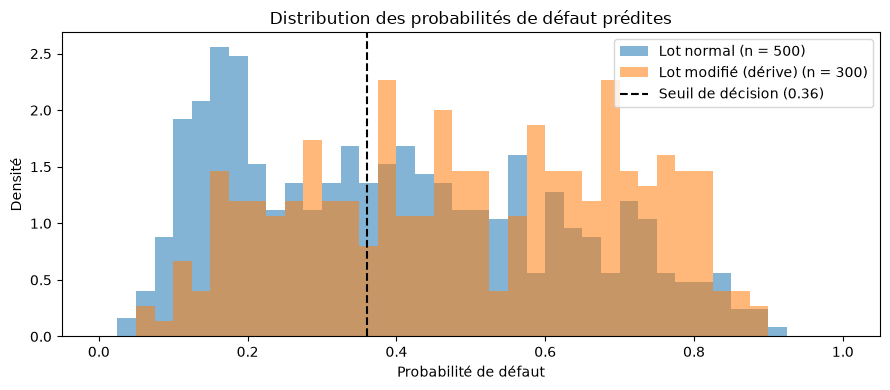

In [6]:
# Indicateurs de suivi par lot, sur les prédictions réussies
ok = production[production["status_code"] == 200]
indicators = ok.groupby("batch").agg(
    predictions=("request_id", "size"),
    score_moyen=("probability_default", "mean"),
    taux_refus=("decision", lambda d: (d == "refused").mean()),
    inference_p50_ms=("inference_time_ms", "median"),
    total_p95_ms=("total_time_ms", lambda t: t.quantile(0.95)),
)
indicators.index.name = "lot"

# Taux d'erreur global : part des requêtes rejetées sur l'ensemble du trafic
error_rate = (production["status_code"] != 200).mean()

print(indicators.round(3).to_string())
print(f"\nTaux d'erreur global : {error_rate:.1%} ({(production['status_code'] != 200).sum()} requêtes rejetées)")

# Distribution des probabilités : lot normal et lot modifié, avec le seuil de décision
fig, ax = plt.subplots(figsize=(9, 4))
bins = np.linspace(0, 1, 41)
for batch, color, label in [("normal", "tab:blue", "Lot normal"), ("drift", "tab:orange", "Lot modifié (dérive)")]:
    scores = ok.loc[ok["batch"] == batch, "probability_default"]
    ax.hist(scores, bins=bins, alpha=0.55, density=True, color=color, label=f"{label} (n = {len(scores)})")
ax.axvline(THRESHOLD, color="black", linestyle="--", label=f"Seuil de décision ({THRESHOLD})")
ax.set_title("Distribution des probabilités de défaut prédites")
ax.set_xlabel("Probabilité de défaut")
ax.set_ylabel("Densité")
ax.legend()
plt.tight_layout()
plt.show()

**Lecture des indicateurs.**

- **Le lot normal se comporte comme le modèle du Projet 6.** Le taux de refus de 51,6 % est cohérent avec celui observé sur le jeu de test au même seuil (environ 50 %) : sans changement de population, la production reproduit le comportement validé.
- **Le lot modifié est jugé nettement plus risqué.** Le score moyen passe de 0,396 à 0,495 et le taux de refus de 51,6 % à 69,3 %. Sur le graphique, la distribution orange est déplacée vers la droite du seuil, alors que le lot normal présente un pic net autour de 0,15 à 0,20, qui correspond aux bons dossiers. Le modèle réagit dans le sens attendu au scénario simulé (clients plus jeunes, revenus plus faibles, montants plus élevés, scores externes plus faibles).
- **Ce changement de distribution des scores est un premier signal d'alerte**, visible immédiatement, sans attendre de connaître les vrais défauts. Il doit être expliqué par l'analyse de dérive des variables (sections suivantes).
- **Le temps de traitement dépend de la charge.** Pour les requêtes manuelles, isolées, l'inférence prend 12,7 ms (médiane) et le traitement total 40,5 ms (95e centile). Pendant la simulation, avec 4 requêtes simultanées sur un seul processeur partagé, ces valeurs montent à environ 33 ms et 180 à 200 ms. La latence en charge sera analysée en phase d'optimisation.
- **Le taux d'erreur est de 0,7 %** : uniquement les requêtes volontairement invalides, toutes rejetées avec le code 422. Aucune erreur serveur (500) ni indisponibilité (503).

## 6. Importance des variables dans le modèle

Une dérive n'a pas le même poids selon la variable concernée : une dérive sur une variable très utilisée par le modèle a beaucoup plus d'effet sur les prédictions qu'une dérive sur une variable presque ignorée. L'importance de chaque variable est mesurée par le **gain** du LightGBM, c'est-à-dire l'amélioration totale apportée par les découpages qui l'utilisent.

Les variables catégorielles sont encodées en plusieurs colonnes (une par catégorie) : leurs gains sont additionnés pour revenir à la variable d'origine.

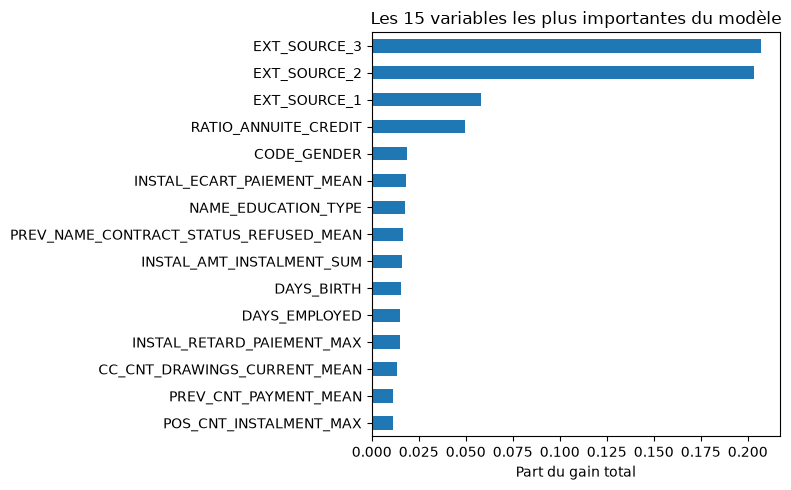

Les 15 variables les plus importantes portent 69% du gain total du modèle


In [7]:
# Importance de chaque variable dans le modèle (gain LightGBM : amélioration apportée
# par les découpages qui utilisent la variable)
booster = model.named_steps["modele"].booster_
gains = booster.feature_importance(importance_type="gain")
encoded_names = column_transformer.get_feature_names_out()

def original_name(encoded: str) -> str:
    """Retrouve la variable d'origine d'une colonne encodée (ex. cat__CODE_GENDER_F -> CODE_GENDER)."""
    branch, name = encoded.split("__", 1)
    if branch == "cat":
        # Nom de la forme VARIABLE_CATEGORIE : on retient la variable la plus longue qui correspond
        return max((c for c in CATEGORICAL if name.startswith(c + "_")), key=len)
    return name

# Les colonnes encodées d'une même variable sont regroupées, puis exprimées en part du total
importance = (
    pd.Series(gains, index=[original_name(n) for n in encoded_names])
    .groupby(level=0).sum()
    .sort_values(ascending=False)
)
importance = importance / importance.sum()
TOP_FEATURES = importance.head(15).index.tolist()

fig, ax = plt.subplots(figsize=(8, 5))
importance.head(15)[::-1].plot.barh(ax=ax, color="tab:blue")
ax.set_title("Les 15 variables les plus importantes du modèle")
ax.set_xlabel("Part du gain total")
plt.tight_layout()
plt.show()

print(f"Les 15 variables les plus importantes portent {importance.head(15).sum():.0%} du gain total du modèle")

**Lecture.** L'importance est très concentrée :
- **EXT_SOURCE_3 et EXT_SOURCE_2**, deux scores externes (notes de solvabilité fournies par des organismes extérieurs), portent à elles seules **environ 41 % du gain total**. Avec EXT_SOURCE_1, les trois scores externes dépassent 46 %.
- **RATIO_ANNUITE_CREDIT** (annuité rapportée au montant du crédit, soit à peu près l'inverse de la durée du prêt) arrive en quatrième position avec environ 5 % : c'est une **variable construite** par le modèle, d'où l'intérêt de l'inclure dans l'analyse de dérive.
- Viennent ensuite des variables de profil (genre, niveau d'études, âge, ancienneté dans l'emploi) et d'historique de remboursement (écarts et retards de paiement, demandes refusées par le passé), chacune autour de 1 à 2 %.
- Les 15 premières variables portent **69 % du gain total**, alors qu'elles ne représentent que 7 % des 206 variables.

**Conséquence pour le suivi.** Une dérive sur les scores externes aurait un effet direct et fort sur les prédictions : ce sont les variables à surveiller en priorité. Le scénario de dérive simulé les dégrade justement de 0,15 point, ce qui explique en grande partie la hausse du score moyen observée à la section 5.

**Point de vigilance.** La présence de **CODE_GENDER** parmi les variables importantes pose une question d'équité : en production réelle, l'usage du genre dans une décision de crédit doit être examiné au regard de la réglementation sur la non-discrimination.

## 7. Préparation des données de production

Les variables reçues par l'API sont stockées en JSON. Elles sont remises sous forme de tableau, avec les mêmes colonnes et dans le même ordre que la référence. Une variable non envoyée devient une valeur manquante, comme dans l'API où le modèle l'impute. Les 7 variables construites sont ensuite calculées par la même classe que dans le modèle, et les deux mêmes traitements que pour la référence sont appliqués (infini remplacé par une valeur manquante, arrondi à 6 décimales).

In [8]:
def to_features(batch_events: pd.DataFrame) -> pd.DataFrame:
    """Remet les entrées JSON d'un lot sous forme de tableau, au format exact de la référence."""
    # Une ligne par requête, colonnes dans l'ordre de l'entraînement ; une variable absente vaut NaN
    raw = pd.DataFrame(list(batch_events["inputs"])).reindex(columns=INPUT_FEATURES)
    numeric_inputs = [c for c in INPUT_FEATURES if c not in CATEGORICAL]
    raw[numeric_inputs] = raw[numeric_inputs].astype(float)
    # Les catégorielles manquantes doivent valoir np.nan (et non None), comme dans l'API
    raw[CATEGORICAL] = raw[CATEGORICAL].astype(object).where(raw[CATEGORICAL].notna(), np.nan)
    # Mêmes traitements que la référence : variables construites, infini remplacé, arrondi
    return feature_builder.transform(raw).replace([np.inf, -np.inf], np.nan).round(6)

current_normal = to_features(ok[ok["batch"] == "normal"])
current_drift = to_features(ok[ok["batch"] == "drift"])

print(f"Production, lot normal : {current_normal.shape[0]} clients x {current_normal.shape[1]} variables")
print(f"Production, lot modifié : {current_drift.shape[0]} clients x {current_drift.shape[1]} variables")

Production, lot normal : 500 clients x 206 variables
Production, lot modifié : 300 clients x 206 variables


## 8. Analyse de dérive : lot normal

Evidently compare chaque variable entre la référence et la production, avec une méthode adaptée à son type et à la taille des échantillons :
- **variables numériques** : la **distance de Wasserstein normalisée**, qui mesure le « coût » pour transformer une distribution en l'autre, rapporté à l'écart-type de la référence ;
- **variables catégorielles** : la **distance de Jensen-Shannon**, qui compare les fréquences des catégories (0 si identiques, 1 si totalement différentes).

Pour ces deux distances, une variable est considérée en dérive si la valeur atteint le **seuil de 0,1**. Pour le lot normal, aucune dérive importante n'est attendue : il est tiré de la même population que l'entraînement.

In [9]:
# Types de variables déclarés à Evidently : il choisit une méthode adaptée à chaque type
definition = DataDefinition(numerical_columns=NUMERIC, categorical_columns=CATEGORICAL)

def run_drift(current: pd.DataFrame, columns: list[str] | None = None):
    """Compare un lot de production à la référence. Retourne le rapport Evidently et un tableau de résultats."""
    cols = columns or list(reference.columns)
    data_def = DataDefinition(
        numerical_columns=[c for c in definition.numerical_columns if c in cols],
        categorical_columns=[c for c in definition.categorical_columns if c in cols],
    )
    snapshot = Report([DataDriftPreset()]).run(
        reference_data=Dataset.from_pandas(reference[cols], data_definition=data_def),
        current_data=Dataset.from_pandas(current[cols], data_definition=data_def),
    )
    # Extraction d'un résultat par variable : méthode, seuil, valeur et verdict
    rows = []
    for metric in snapshot.dict()["metrics"]:
        config = metric["config"]
        if config.get("type", "").endswith("ValueDrift"):
            method, threshold, value = config["method"], config["threshold"], metric["value"]
            # Deux familles de méthodes : une p-value (dérive si elle est PETITE)
            # ou une distance (dérive si elle est GRANDE)
            drifted = value < threshold if "p_value" in method else value >= threshold
            rows.append({"variable": config["column"], "méthode": method, "seuil": threshold,
                         "valeur": value, "dérive": drifted})
    results = pd.DataFrame(rows).set_index("variable")
    results["importance"] = importance.reindex(results.index).fillna(0)
    return snapshot, results.sort_values(["dérive", "importance"], ascending=False)

snapshot_normal, drift_normal = run_drift(current_normal)
n_drift = int(drift_normal["dérive"].sum())
share_drift = drift_normal.loc[drift_normal["dérive"], "importance"].sum()
print(f"Lot normal : {n_drift} variables en dérive sur {len(drift_normal)} ({n_drift / len(drift_normal):.1%})")
print(f"Part de l'importance du modèle portée par ces variables : {share_drift:.1%}\n")
print("Les 15 variables les plus importantes :")
print(drift_normal.loc[TOP_FEATURES, ["méthode", "valeur", "seuil", "dérive"]].round(3).to_string())

Lot normal : 11 variables en dérive sur 206 (5.3%)
Part de l'importance du modèle portée par ces variables : 1.5%

Les 15 variables les plus importantes :
                                                              méthode  valeur  seuil  dérive
variable                                                                                    
EXT_SOURCE_3                            Wasserstein distance (normed)   0.050    0.1   False
EXT_SOURCE_2                            Wasserstein distance (normed)   0.037    0.1   False
EXT_SOURCE_1                            Wasserstein distance (normed)   0.064    0.1   False
RATIO_ANNUITE_CREDIT                    Wasserstein distance (normed)   0.052    0.1   False
CODE_GENDER                                   Jensen-Shannon distance   0.019    0.1   False
INSTAL_ECART_PAIEMENT_MEAN              Wasserstein distance (normed)   0.071    0.1   False
NAME_EDUCATION_TYPE                           Jensen-Shannon distance   0.030    0.1   False
PREV_NAM

**Lecture : pas de dérive sur le lot normal.**

- **Aucune des 15 variables les plus importantes ne dérive.** Toutes les distances restent nettement sous le seuil de 0,1 : de 0,019 pour CODE_GENDER à 0,085 pour DAYS_BIRTH. Les scores externes, qui portent près de la moitié de l'importance du modèle, sont très stables (0,037 à 0,064).
- **11 variables sur 206 (5,3 %) dépassent le seuil**, mais elles ne portent que **1,5 % de l'importance du modèle**. Ce sont des **fausses alertes liées à l'échantillonnage** : avec 500 clients seulement, la distribution observée fluctue naturellement autour de celle de la référence, et quelques variables franchissent le seuil par hasard. Une proportion d'environ 5 % est l'ordre de grandeur attendu dans ce cas.
- **Au niveau du jeu de données, il n'y a pas de dérive** : Evidently considère qu'un jeu de données dérive lorsqu'au moins la moitié des variables dérivent ; on en est très loin (5,3 %).

**Enseignement pour le suivi.** Le nombre de variables en dérive ne suffit pas : il faut le **pondérer par l'importance des variables**. Une alerte sur des variables secondaires, avec un petit échantillon, appelle une simple surveillance ; une alerte sur les variables importantes appelle une analyse.

## 9. Analyse de dérive : lot modifié

Le lot modifié simule un changement de population, comme après une campagne commerciale en ligne : clients plus jeunes (âge réduit d'un tiers), revenus plus modestes (-25 %), montants demandés plus élevés (+50 % pour le crédit et l'annuité), scores externes 2 et 3 plus faibles (-0,15) et un client sur deux en crédit renouvelable. L'analyse doit détecter ces changements, y compris sur les variables construites qui en découlent (âge en années, ratios).

In [10]:
snapshot_drift, drift_drift = run_drift(current_drift)
n_drift = int(drift_drift["dérive"].sum())
share_drift = drift_drift.loc[drift_drift["dérive"], "importance"].sum()
print(f"Lot modifié : {n_drift} variables en dérive sur {len(drift_drift)} ({n_drift / len(drift_drift):.1%})")
print(f"Part de l'importance du modèle portée par ces variables : {share_drift:.1%}\n")
print("Variables en dérive, classées par importance dans le modèle (15 premières) :")
print(drift_drift[drift_drift["dérive"]].head(15)[["méthode", "valeur", "seuil", "importance"]].round(3).to_string())

Lot modifié : 51 variables en dérive sur 206 (24.8%)
Part de l'importance du modèle portée par ces variables : 57.6%

Variables en dérive, classées par importance dans le modèle (15 premières) :
                                                      méthode  valeur  seuil  importance
variable                                                                                
EXT_SOURCE_3                    Wasserstein distance (normed)   0.676    0.1       0.207
EXT_SOURCE_2                    Wasserstein distance (normed)   0.751    0.1       0.203
RATIO_ANNUITE_CREDIT            Wasserstein distance (normed)   0.113    0.1       0.050
DAYS_BIRTH                      Wasserstein distance (normed)   1.190    0.1       0.016
PREV_CNT_PAYMENT_MEAN           Wasserstein distance (normed)   0.103    0.1       0.012
AMT_ANNUITY                     Wasserstein distance (normed)   0.912    0.1       0.011
PREV_ECART_CREDIT_DEMANDE_MIN   Wasserstein distance (normed)   0.159    0.1       0.008
AGE_

**Contrôle du scénario.** Le tableau suivant reprend les variables modifiées directement par le scénario, puis les variables construites qui en dépendent, pour vérifier que chaque changement simulé est bien détecté.

In [11]:
# Variables modifiées par le scénario, puis variables construites qui en découlent
scenario = {
    "EXT_SOURCE_2": "modifiée (-0,15)",
    "EXT_SOURCE_3": "modifiée (-0,15)",
    "DAYS_BIRTH": "modifiée (âge réduit d'un tiers)",
    "AMT_INCOME_TOTAL": "modifiée (-25 %)",
    "AMT_CREDIT": "modifiée (+50 %)",
    "AMT_ANNUITY": "modifiée (+50 %)",
    "NAME_CONTRACT_TYPE": "modifiée (1 client sur 2 en crédit renouvelable)",
    "AGE_ANNEES": "construite à partir de DAYS_BIRTH",
    "RATIO_CREDIT_REVENU": "construite : crédit / revenu",
    "RATIO_ANNUITE_REVENU": "construite : annuité / revenu",
    "RATIO_ANNUITE_CREDIT": "construite : annuité / crédit",
    "RATIO_EMPLOI_AGE": "construite : ancienneté / âge",
}
check = drift_drift.loc[list(scenario), ["valeur", "dérive", "importance"]].copy()
check.insert(0, "changement simulé", pd.Series(scenario))
# Pour comparaison : la valeur de la même variable dans le lot normal
check.insert(2, "valeur (lot normal)", drift_normal.loc[list(scenario), "valeur"])
print(check.round(3).to_string())

                                                     changement simulé  valeur  valeur (lot normal)  dérive  importance
variable                                                                                                               
EXT_SOURCE_2                                          modifiée (-0,15)   0.751                0.037    True       0.203
EXT_SOURCE_3                                          modifiée (-0,15)   0.676                0.050    True       0.207
DAYS_BIRTH                            modifiée (âge réduit d'un tiers)   1.190                0.085    True       0.016
AMT_INCOME_TOTAL                                      modifiée (-25 %)   0.443                0.047    True       0.001
AMT_CREDIT                                            modifiée (+50 %)   0.706                0.040    True       0.007
AMT_ANNUITY                                           modifiée (+50 %)   0.912                0.035    True       0.011
NAME_CONTRACT_TYPE    modifiée (1 client

**Lecture : dérive nettement détectée sur le lot modifié.**

**1. Tous les changements simulés sont détectés.** Les 7 variables modifiées par le scénario dépassent largement le seuil (de 0,364 à 1,190), alors que les mêmes variables restent entre 0,011 et 0,085 dans le lot normal. Le contraste est sans ambiguïté.

**2. La dérive se propage aux variables construites, souvent en s'amplifiant.** Le ratio annuité sur revenu atteint 2,120, la plus forte dérive : son numérateur augmente de 50 % et son dénominateur baisse de 25 %, ce qui double la valeur du ratio. De même, le ratio crédit sur revenu atteint 1,545. Analyser les variables construites, et pas seulement les variables reçues, est donc indispensable.

**3. Un contrôle de cohérence : le ratio annuité sur crédit.** Le scénario multiplie l'annuité et le crédit par le même facteur (1,5) : leur rapport est mathématiquement inchangé. Sa distance (0,113) est pourtant juste au-dessus du seuil. Cet écart ne vient pas du scénario, mais de l'échantillonnage : le lot modifié compte seulement 300 clients, différents de ceux du lot normal, et les fluctuations naturelles sont plus fortes sur un petit échantillon. C'est une fausse alerte, à la limite du seuil. Elle rappelle qu'un seuil unique ne remplace pas l'analyse.

**4. Le critère décisif : l'importance des variables en dérive.** 51 variables dérivent (24,8 %), contre 11 dans le lot normal. Surtout, ces variables portent **57,6 % de l'importance du modèle**, contre 1,5 % pour le lot normal. Les deux scores externes, qui portent à eux seuls 41 % de l'importance, dérivent fortement (0,676 et 0,751) : les prédictions sont directement affectées, ce qui explique la hausse du score moyen et du taux de refus observée à la section 5.

**5. Au niveau du jeu de données**, Evidently ne conclut pas à une dérive globale, car moins de la moitié des variables dérivent (24,8 %). Ce critère global, fondé sur un simple décompte, est trompeur ici : il ignore que les variables touchées sont les plus importantes pour le modèle. D'où l'intérêt de **pondérer la dérive par l'importance**.

## 10. Visualisation des distributions

Les histogrammes comparent la référence, le lot normal et le lot modifié pour quatre variables du scénario : une variable modifiée directement (score externe 2), une variable construite à partir d'une autre (âge en années), et deux variables construites qui combinent plusieurs modifications (ratios). Les 1 % de valeurs les plus extrêmes sont regroupées aux bornes pour lisser l'affichage.

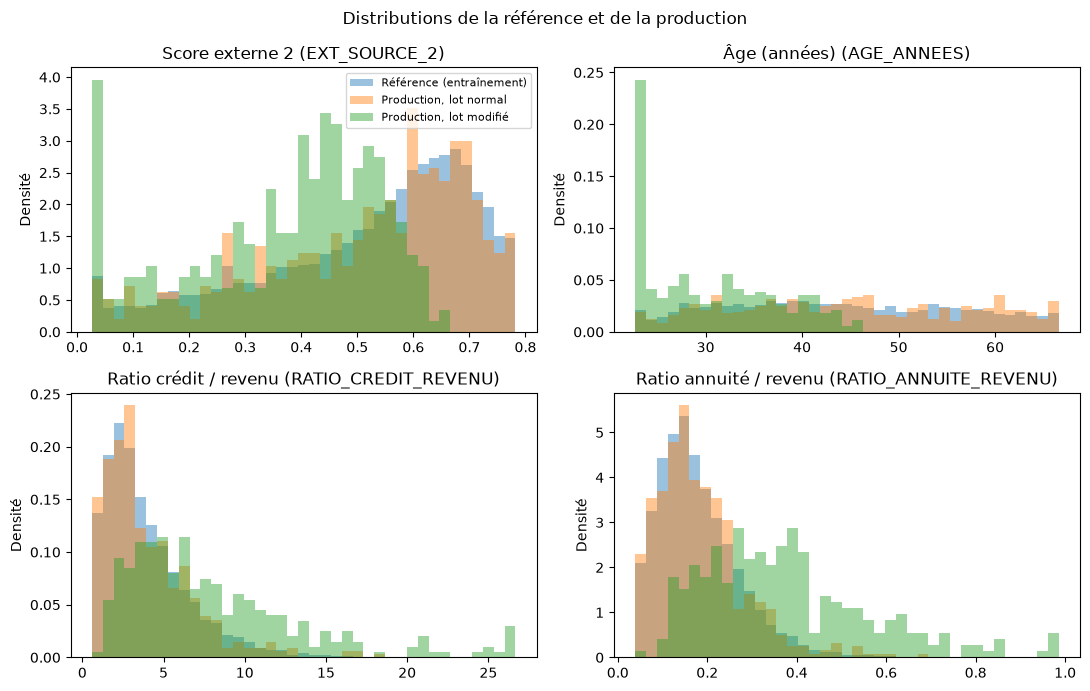

In [12]:
# Comparaison des distributions pour quatre variables touchées par le scénario
fig, axes = plt.subplots(2, 2, figsize=(11, 7))
variables = {
    "EXT_SOURCE_2": "Score externe 2",
    "AGE_ANNEES": "Âge (années)",
    "RATIO_CREDIT_REVENU": "Ratio crédit / revenu",
    "RATIO_ANNUITE_REVENU": "Ratio annuité / revenu",
}
for ax, (col, label) in zip(axes.ravel(), variables.items()):
    ref_values = reference[col].dropna()
    # Bornes communes sans les valeurs extrêmes (1 % de chaque côté), pour comparer les formes
    low, high = ref_values.quantile([0.01, 0.99])
    high = max(high, current_drift[col].quantile(0.99))
    bins = np.linspace(low, high, 40)
    ax.hist(ref_values.clip(low, high), bins=bins, density=True, alpha=0.45, label="Référence (entraînement)")
    ax.hist(current_normal[col].dropna().clip(low, high), bins=bins, density=True, alpha=0.45, label="Production, lot normal")
    ax.hist(current_drift[col].dropna().clip(low, high), bins=bins, density=True, alpha=0.45, label="Production, lot modifié")
    ax.set_title(f"{label} ({col})")
    ax.set_ylabel("Densité")
axes[0, 0].legend(fontsize=8)
fig.suptitle("Distributions de la référence et de la production")
plt.tight_layout()
plt.show()

## 11. Rapports Evidently

Evidently produit des rapports HTML interactifs : pour chaque variable, la valeur de la distance, le seuil, et les histogrammes superposés de la référence et de la production. Pour garder des fichiers de taille raisonnable, les rapports interactifs sont limités aux 15 variables les plus importantes (un rapport sur les 206 variables pèserait plusieurs dizaines de mégaoctets). Les tableaux complets des 206 variables sont enregistrés au format CSV, pour la traçabilité de l'analyse.

In [13]:
# Rapports interactifs, limités aux 15 variables les plus importantes, plus les variables
# du scénario : ce sont celles qu'un analyste consulterait en premier
report_columns = list(dict.fromkeys(TOP_FEATURES + list(scenario)))
for name, current in [("normal", current_normal), ("modifie", current_drift)]:
    snapshot, _ = run_drift(current, columns=report_columns)
    path = REPORTS_DIR / f"rapport_derive_lot_{name}.html"
    snapshot.save_html(str(path))
    print(f"Rapport enregistré : {path.relative_to(PROJECT_ROOT)} ({path.stat().st_size / 1e6:.1f} Mo)")

# Tableaux complets des 206 variables
drift_normal.to_csv(REPORTS_DIR / "derive_lot_normal.csv")
drift_drift.to_csv(REPORTS_DIR / "derive_lot_modifie.csv")
print("Tableaux complets enregistrés : derive_lot_normal.csv, derive_lot_modifie.csv")

Rapport enregistré : monitoring/reports/rapport_derive_lot_normal.html (5.1 Mo)
Rapport enregistré : monitoring/reports/rapport_derive_lot_modifie.html (5.0 Mo)
Tableaux complets enregistrés : derive_lot_normal.csv, derive_lot_modifie.csv


**Lecture des distributions.**

- **La référence et le lot normal se superposent presque parfaitement** sur les quatre variables : c'est l'image d'une production sans dérive.
- **Score externe 2** : la distribution du lot modifié est décalée d'environ 0,15 vers la gauche, ce qui correspond au scénario. Le **pic à gauche** n'est pas une anomalie des données : les clients dont le score, diminué de 0,15, serait devenu négatif ont été ramenés à 0 par le scénario, et l'affichage regroupe ces valeurs à la borne basse du graphique.
- **Âge** : le lot modifié est concentré sur les jeunes clients. Le **pic à gauche** a la même origine : les âges réduits d'un tiers descendent souvent sous la borne basse du graphique (le 1er centile de la référence, autour de 22 ans) et sont regroupés à cette borne.
- **Ratios crédit sur revenu et annuité sur revenu** : la distribution du lot modifié s'étale nettement vers la droite, avec une longue traîne. Ces ratios mesurent l'effort financier demandé au client ; leur hausse traduit des demandes plus lourdes rapportées aux revenus, ce qui explique que le modèle juge ces dossiers plus risqués.

**Rapports interactifs.** Les rapports Evidently (`monitoring/reports/rapport_derive_lot_normal.html` et `rapport_derive_lot_modifie.html`) détaillent, pour les 15 variables les plus importantes et les variables du scénario, la distance mesurée, le seuil et les histogrammes de la référence et de la production. Les tableaux complets des 206 variables sont dans les fichiers CSV du même dossier.

## 12. Effet sur la performance réelle du modèle

En production réelle, on ne sait si un client fait défaut que des mois après la décision : la dérive des données sert justement de signal d'alerte précoce. La simulation permet ici d'aller plus loin, car elle connaît la vraie cible de chaque client : on peut mesurer directement la performance du modèle sur chaque lot.

**Attention à l'interprétation du lot modifié.** Dans la simulation, les variables des clients sont modifiées, mais leur vraie cible reste celle du client d'origine. Le lot modifié ne représente donc pas une population réellement plus risquée : il ressemble plutôt à un **changement dans la mesure des données** (par exemple, un fournisseur de scores externes qui change d'échelle, ou une erreur de saisie systématique). C'est l'un des cas les plus dangereux en production : les données changent, mais pas le risque réel.

In [14]:
from sklearn.metrics import precision_score

# Performance réelle sur les données de production : la simulation connaît la vraie cible
rows = []
for batch, label in [("normal", "Lot normal"), ("drift", "Lot modifié")]:
    events = ok[ok["batch"] == batch].dropna(subset=["target"])
    y_true = events["target"].astype(int)
    y_score = events["probability_default"]
    y_pred = (y_score >= THRESHOLD).astype(int)
    rows.append({
        "lot": label,
        "clients": len(events),
        "défauts réels": int(y_true.sum()),
        "taux de défaut": y_true.mean(),
        "AUC": roc_auc_score(y_true, y_score),
        "rappel": recall_score(y_true, y_pred),
        "précision": precision_score(y_true, y_pred),
        "taux de refus": y_pred.mean(),
    })
performance = pd.DataFrame(rows).set_index("lot")
print(performance.round(3).to_string())
print("\nRappel sur le jeu de test du Projet 6 : AUC 0,786, rappel 0,852, précision 0,138")

             clients  défauts réels  taux de défaut    AUC  rappel  précision  taux de refus
lot                                                                                         
Lot normal       500             39           0.078  0.796   0.897      0.136          0.516
Lot modifié      300             22           0.073  0.767   0.955      0.101          0.693

Rappel sur le jeu de test du Projet 6 : AUC 0,786, rappel 0,852, précision 0,138


**Lecture de la performance réelle.**

**Lot normal : le modèle reproduit les performances validées au Projet 6.** L'AUC (0,796) et la précision (0,136) sont très proches de celles du jeu de test (0,786 et 0,138). Le rappel est un peu plus élevé (0,897 contre 0,852), mais il repose sur seulement 39 défauts : un défaut détecté de plus ou de moins le fait varier de 2,6 points. En production, sans changement de population, le modèle se comporte comme prévu.

**Lot modifié : le risque réel n'a pas changé, mais les décisions, si.**
- Le taux de défaut réel est le même (7,3 % contre 7,8 %) : ce sont des clients du même type, dont seules les données ont été modifiées.
- Le taux de refus passe pourtant de 51,6 % à 69,3 %. Le modèle refuse environ 187 des 278 bons clients (67 %), contre 223 sur 461 (48 %) dans le lot normal.
- Le rappel progresse légèrement (0,955) : en refusant davantage, le modèle attrape presque tous les défauts. Mais la **précision chute de 0,136 à 0,101** : parmi les clients refusés, la part de vrais défauts diminue nettement.
- L'AUC baisse de 0,796 à 0,767 : le modèle classe moins bien les clients, car les variables qu'il utilise le plus (les scores externes) ne mesurent plus la même chose.

**Enseignement principal.** Une dérive des données ne provoque **aucune erreur technique** : l'API répond normalement, avec le code 200, et les temps de réponse sont stables. Le dommage est silencieux : des décisions décalées, ici un grand nombre de bons clients refusés, donc une perte de chiffre d'affaires pour Prêt à Dépenser. Seul un suivi des données et des décisions permet de le détecter, et bien avant que les vrais défauts ne soient connus.

**Limite.** Les échantillons sont petits (500 et 300 clients, 39 et 22 défauts) : les écarts de performance sont indicatifs. En production réelle, ces indicateurs seraient suivis sur des volumes plus importants et sur une durée plus longue.

## 13. Conclusion et recommandations

**Ce que montre l'analyse.**
1. Sur le lot normal, la production ressemble à l'entraînement : aucune des variables importantes ne dérive, les quelques alertes (5 % des variables, 1,5 % de l'importance) relèvent des fluctuations d'échantillonnage, et la performance réelle est celle validée au Projet 6.
2. Sur le lot modifié, la dérive est détectée sans ambiguïté : toutes les variables du scénario dépassent largement le seuil, la dérive se propage et s'amplifie dans les variables construites, et les variables en dérive portent 58 % de l'importance du modèle.
3. La dérive n'a provoqué aucune erreur technique, mais elle a modifié les décisions : taux de refus de 69 % au lieu de 52 %, précision en baisse, de nombreux bons clients refusés.

**Recommandations pour le suivi en production.**

| Indicateur | Fréquence | Seuil d'alerte proposé | Pourquoi |
|---|---|---|---|
| Score moyen et taux de refus | Quotidienne | Écart de plus de 5 points par rapport à la référence | Signal le plus rapide, visible avant toute analyse détaillée |
| Dérive pondérée par l'importance (part de l'importance portée par les variables en dérive) | Hebdomadaire | Plus de 20 % | Plus fiable que le simple nombre de variables en dérive, qui ignore leur poids dans le modèle |
| Dérive des scores externes (EXT_SOURCE_1, 2 et 3) | Hebdomadaire | Distance supérieure à 0,1 | Ces trois variables portent près de la moitié de l'importance du modèle |
| Temps de traitement (95e centile) et taux d'erreur | En continu | Plus de 300 ms ; plus de 1 % d'erreurs 5xx | Qualité de service de l'API |
| Performance réelle (AUC, rappel, précision) | Mensuelle, dès que les défauts sont connus | AUC inférieure à 0,75 ; rappel inférieur à 0,80 | Seule mesure directe de la qualité des décisions |

**Que faire en cas d'alerte ?**
1. **Vérifier les données avant le modèle** : un changement brutal (fournisseur de scores, format d'une variable, erreur de saisie) se corrige à la source, sans réentraîner.
2. **Si la population a réellement changé**, réentraîner le modèle sur des données récentes, le comparer au modèle en production sur les mêmes données de test, et ne le déployer que s'il fait mieux.
3. **Revoir le seuil de décision** si le coût métier des erreurs a changé.

**Limites de l'analyse.**
- Le trafic est simulé : le scénario de dérive est volontairement marqué, pour vérifier que la détection fonctionne.
- Les échantillons de production sont petits ; sur 300 à 500 clients, environ 5 % de fausses alertes sont attendues.
- Les requêtes rejetées ne renvoient pas d'identifiant au client : elles ne peuvent pas être reliées à leur origine. Amélioration prévue : renvoyer l'identifiant de requête dans toutes les réponses, y compris les erreurs.
- La dérive du concept (un changement du lien entre les variables et le défaut) ne peut être mesurée qu'avec la vraie cible, donc avec retard.